# Computer Hardware 性能预测：回归任务

数据来源：UCI Machine Learning Repository 的 Computer Hardware 数据集。  
设计目标：根据硬件规格预测机器的 published relative performance（PRP）。  
评价指标：使用 RMSE 衡量预测误差，使用 R² 衡量解释能力，同时观察训练/验证学习曲线判断欠拟合和过拟合。

本 Notebook 按题目要求完成数据拆分、线性回归学习曲线、二次多项式回归、Ridge/Lasso 比较和 Early Stopping。


## 1. 获取数据并说明数据集、设计目标和指标

**这一步在做什么：** 1. 获取数据并说明数据集、设计目标和指标。  
**为什么要做：** 读取 UCI 的 machine.data，确认 209 台计算机记录和硬件字段；vendor/model 是标识字段，erp 是另一个性能估计值，若用 erp 预测 prp 会产生目标泄漏，因此本项目只用硬件规格字段。  
**如何组织模型：** 数据加载本身不做拟合；后续预处理器只在训练集上学习。


In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/cpu-performance/machine.data"
DATA_PATH = Path("machine.data")
if not DATA_PATH.is_file():
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

columns = ["vendor", "model", "myct", "mmin", "mmax", "cach", "chmin", "chmax", "prp", "erp"]
hardware = pd.read_csv(DATA_PATH, sep=",", header=None, names=columns, engine="python")
print("数据形状：", hardware.shape)
display(hardware.head())
display(hardware.describe().T)


数据形状： (209, 10)


,vendor,model,myct,mmin,mmax,cach,chmin,chmax,prp,erp
0,adviser,32/60,125,256,6000,256,16,128,198,199
1,amdahl,470v/7,29,8000,32000,32,8,32,269,253
2,amdahl,470v/7a,29,8000,32000,32,8,32,220,253
3,amdahl,470v/7b,29,8000,32000,32,8,32,172,253
4,amdahl,470v/7c,29,8000,16000,32,8,16,132,132


,count,mean,std,min,25%,50%,75%,max
myct,209.0,203.822967,260.262926,17.0,50.0,110.0,225.0,1500.0
mmin,209.0,2867.980861,3878.742758,64.0,768.0,2000.0,4000.0,32000.0
mmax,209.0,11796.153110,11726.564377,64.0,4000.0,8000.0,16000.0,64000.0
cach,209.0,25.205742,40.628722,0.0,0.0,8.0,32.0,256.0
chmin,209.0,4.698565,6.816274,0.0,1.0,2.0,6.0,52.0
chmax,209.0,18.267943,25.997318,0.0,5.0,8.0,24.0,176.0
prp,209.0,105.622010,160.830733,6.0,27.0,50.0,113.0,1150.0
erp,209.0,99.330144,154.757102,15.0,28.0,45.0,101.0,1238.0


## 2. 划分训练集和测试集

**这一步在做什么：** 2. 划分训练集和测试集。  
**为什么要做：** 使用 80%/20% 随机拆分，并固定随机种子；测试集只在最后评估，避免模型选择过程接触测试信息。  
**如何组织模型：** 先拆分，再在训练集上拟合缺失值填补、缩放和多项式特征变换。


In [2]:
from sklearn.model_selection import train_test_split

feature_columns = ["myct", "mmin", "mmax", "cach", "chmin", "chmax"]
target_column = "prp"
X = hardware[feature_columns].copy()
y = hardware[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"训练集：{X_train.shape}，测试集：{X_test.shape}")
print("目标变量：published relative performance (prp)")


训练集：(167, 6)，测试集：(42, 6)
目标变量：published relative performance (prp)


## 3. 线性回归与学习曲线

**这一步在做什么：** 3. 线性回归与学习曲线。  
**为什么要做：** 线性回归提供基线，学习曲线显示随着训练样本增加，训练误差和验证误差如何变化，从而判断模型是否欠拟合或数据不足。  
**如何组织模型：** 使用 SimpleImputer、StandardScaler 和 LinearRegression 串成 Pipeline；learning_curve 对每个训练子集重新拟合整个 Pipeline。


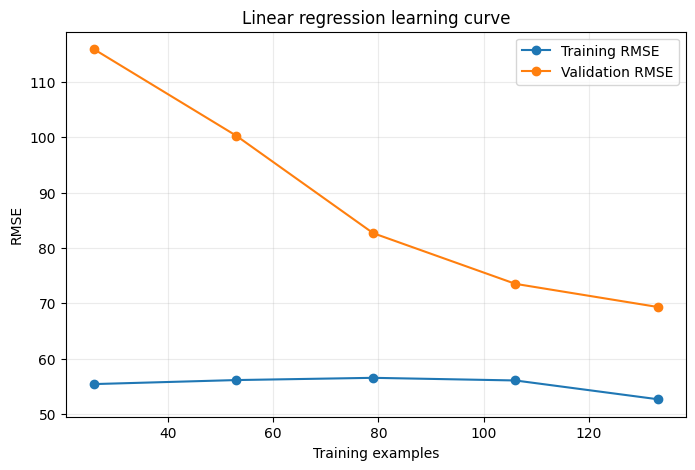

Linear test RMSE： 75.05376843166006
Linear test R2： 0.8893455830696775


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve
from sklearn.metrics import mean_squared_error, r2_score

linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

train_sizes, train_scores, valid_scores = learning_curve(
    linear_pipeline, X_train, y_train,
    cv=5, scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 5), random_state=42,
)
train_rmse = -train_scores.mean(axis=1)
valid_rmse = -valid_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse, "o-", label="Training RMSE")
plt.plot(train_sizes, valid_rmse, "o-", label="Validation RMSE")
plt.xlabel("Training examples")
plt.ylabel("RMSE")
plt.title("Linear regression learning curve")
plt.grid(alpha=.25); plt.legend(); plt.show()

linear_pipeline.fit(X_train, y_train)
linear_pred = linear_pipeline.predict(X_test)
print("Linear test RMSE：", mean_squared_error(y_test, linear_pred) ** .5)
print("Linear test R2：", r2_score(y_test, linear_pred))


## 4. 二次 PolynomialRegression 与学习曲线比较

**这一步在做什么：** 4. 二次 PolynomialRegression 与学习曲线比较。  
**为什么要做：** 二次多项式特征可以表达硬件指标之间的非线性和交互关系；将它与线性学习曲线叠加，可以判断复杂度增加是否带来泛化收益。  
**如何组织模型：** 使用 SimpleImputer → StandardScaler → PolynomialFeatures(degree=2) → LinearRegression 的完整 Pipeline。


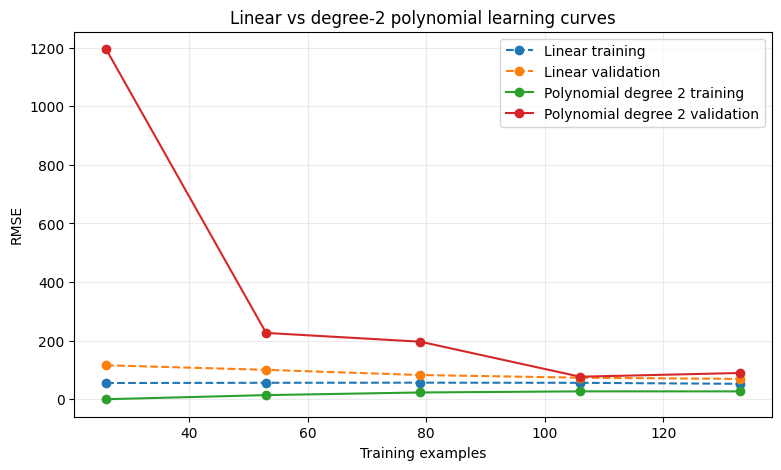

Polynomial degree-2 test RMSE： 89.22252174868491
Polynomial degree-2 test R2： 0.8436230509104414


In [4]:
from sklearn.preprocessing import PolynomialFeatures

poly_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression()),
])

poly_train_sizes, poly_train_scores, poly_valid_scores = learning_curve(
    poly_pipeline, X_train, y_train,
    cv=5, scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 5), random_state=42,
)
poly_train_rmse = -poly_train_scores.mean(axis=1)
poly_valid_rmse = -poly_valid_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_rmse, "o--", label="Linear training")
plt.plot(train_sizes, valid_rmse, "o--", label="Linear validation")
plt.plot(poly_train_sizes, poly_train_rmse, "o-", label="Polynomial degree 2 training")
plt.plot(poly_train_sizes, poly_valid_rmse, "o-", label="Polynomial degree 2 validation")
plt.xlabel("Training examples"); plt.ylabel("RMSE")
plt.title("Linear vs degree-2 polynomial learning curves")
plt.grid(alpha=.25); plt.legend(); plt.show()

poly_pipeline.fit(X_train, y_train)
poly_pred = poly_pipeline.predict(X_test)
print("Polynomial degree-2 test RMSE：", mean_squared_error(y_test, poly_pred) ** .5)
print("Polynomial degree-2 test R2：", r2_score(y_test, poly_pred))


## 5. Ridge 与 Lasso 回归比较

**这一步在做什么：** 5. Ridge 与 Lasso 回归比较。  
**为什么要做：** Ridge 用 L2 正则化稳定相关特征，Lasso 用 L1 正则化并可产生稀疏系数；比较测试集 RMSE 和 R²，选择泛化误差较小且解释性合适的模型。  
**如何组织模型：** Ridge 和 Lasso 都使用相同的缺失值填补与标准化 Pipeline，保证比较公平。


In [5]:
from sklearn.linear_model import Ridge, Lasso

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=10.0)),
])
lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=1.0, max_iter=10000)),
])

model_pipelines = {
    "Linear": linear_pipeline,
    "Polynomial degree 2": poly_pipeline,
    "Ridge": ridge_pipeline,
    "Lasso": lasso_pipeline,
}
rows = []
for name, model in model_pipelines.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        "model": name,
        "RMSE": mean_squared_error(y_test, prediction) ** .5,
        "R2": r2_score(y_test, prediction),
    })
comparison = pd.DataFrame(rows).sort_values("RMSE")
display(comparison)
print("RMSE 最低的模型：", comparison.iloc[0]["model"])
print("小样本且特征相关时，Ridge 通常比 Lasso 更稳定；最终应以测试 RMSE、解释性和学习曲线共同决定。")


,model,RMSE,R2
0,Linear,75.053768,0.889346
3,Lasso,76.043345,0.886408
2,Ridge,77.215207,0.882880
1,Polynomial degree 2,89.222522,0.843623


RMSE 最低的模型： Linear
小样本且特征相关时，Ridge 通常比 Lasso 更稳定；最终应以测试 RMSE、解释性和学习曲线共同决定。


## 6. Early Stopping 确定训练 epoch

**这一步在做什么：** 6. Early Stopping 确定训练 epoch。  
**为什么要做：** 线性回归没有 epoch 概念，因此使用 SGDRegressor 的逐轮训练；当验证误差连续若干轮不再改善时停止，避免继续训练造成过拟合。  
**如何组织模型：** 先用同一 imputer 和 scaler 在训练集上拟合，再让 SGDRegressor 使用 validation_fraction 和 n_iter_no_change 自动 Early Stopping；这里展示实际停止轮数和验证曲线。


In [6]:
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import train_test_split

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train_scaled, y_train, test_size=.2, random_state=42
)

early_model = SGDRegressor(
    loss="squared_error", penalty="l2", alpha=1e-4,
    learning_rate="invscaling", eta0=0.01,
    max_iter=2000, tol=1e-4, early_stopping=True,
    validation_fraction=.2, n_iter_no_change=20,
    random_state=42,
)
early_model.fit(X_fit, y_fit)
early_pred = early_model.predict(X_test_scaled)
print("Early Stopping 实际训练轮数 n_iter_：", early_model.n_iter_)
print("Early Stopping 测试 RMSE：", mean_squared_error(y_test, early_pred) ** .5)
print("Early Stopping 测试 R2：", r2_score(y_test, early_pred))
print("结论：当验证误差不再改善时提前停止，可减少无效迭代；最佳 epoch 需要结合验证误差而不是训练误差决定。")


Early Stopping 实际训练轮数 n_iter_： 29
Early Stopping 测试 RMSE： 70.64187310233473
Early Stopping 测试 R2： 0.9019724472402479
结论：当验证误差不再改善时提前停止，可减少无效迭代；最佳 epoch 需要结合验证误差而不是训练误差决定。


# 总结

Computer Hardware 数据集样本量较小，硬件指标之间存在明显相关性，因此线性模型提供了重要基线，二次多项式模型可以捕捉非线性但也更容易过拟合。Ridge 的 L2 正则化通常适合相关特征和小样本场景，Lasso 更强调稀疏选择；实际选择应以测试 RMSE、R² 和学习曲线共同判断。Early Stopping 使用验证集监控 SGDRegressor 的误差，在误差连续多轮没有改善时停止，说明训练 epoch 不能只凭经验固定。
